# Topic Modeling: Discovering Themes in Text

Topic modeling is unsupervised learning for text. Instead of predicting a label, it discovers latent
themes that explain why documents share words. It is useful for exploring large collections of
articles, reviews, support tickets, or research abstracts.

This notebook compares Latent Dirichlet Allocation (LDA) and non-negative matrix factorization (NMF)
on a synthetic corpus with known topics.

## Learning objectives

By the end of this notebook you can:

- convert text into a document-term matrix;
- explain the bag-of-words assumption and its limitations;
- fit LDA and NMF topic models;
- inspect topic-word distributions and document-topic mixtures;
- choose the number of topics using perplexity and interpretability;
- evaluate discovered topics against known labels.

## 1. From text to a document-term matrix

Topic models work with counts or TF-IDF weights. `CountVectorizer` builds a matrix where rows are
documents and columns are vocabulary terms. `TfidfVectorizer` additionally down-weights terms that
appear in many documents.

Both ignore word order: this is the **bag-of-words** assumption. It is a strong simplification, but it
is often enough for topic discovery.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.decomposition import LatentDirichletAllocation, NMF
from sklearn.metrics import adjusted_rand_score

np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(42)

## 2. A synthetic corpus with known topics

We generate 100 documents for each of four topics: space, food, sports, and technology. Each document
is a random mixture of topic words plus common stop words. Because we know the true topic, we can check
whether the model recovers the structure.

In [2]:
topic_words = {
    "space": "rocket orbit astronaut planet galaxy telescope satellite launch moon nasa".split(),
    "food": "recipe kitchen garlic pasta bake oven flavor spice restaurant chef".split(),
    "sports": "match team coach goal score league player tournament stadium training".split(),
    "technology": "software computer algorithm data network code server model cloud".split(),
}
common_words = "the a and to of in is for on with".split()
topic_names = list(topic_words)

documents = []
true_topics = []
for _ in range(100):
    for topic_id, name in enumerate(topic_names):
        words = list(rng.choice(topic_words[name], size=18, replace=True))
        words += list(rng.choice(common_words, size=8, replace=True))
        rng.shuffle(words)
        documents.append(" ".join(words))
        true_topics.append(topic_id)

true_topics = np.array(true_topics)
print("number of documents:", len(documents))
print("example document:", documents[0][:120], "...")

number of documents: 400
example document: rocket of is to astronaut for launch galaxy nasa orbit satellite rocket on moon rocket launch telescope launch in launch ...


In [3]:
count_vectorizer = CountVectorizer(
    stop_words="english", max_df=0.9, min_df=2
)
X_counts = count_vectorizer.fit_transform(documents)
feature_names = count_vectorizer.get_feature_names_out()

print("document-term matrix:", X_counts.shape)
print("vocabulary size:", len(feature_names))
print("first 20 terms:", feature_names[:20])

document-term matrix: (400, 39)
vocabulary size: 39
first 20 terms: ['algorithm' 'astronaut' 'bake' 'chef' 'cloud' 'coach' 'code' 'computer'
 'data' 'flavor' 'galaxy' 'garlic' 'goal' 'kitchen' 'launch' 'league'
 'match' 'model' 'moon' 'nasa']


## 3. Latent Dirichlet Allocation

LDA assumes each document is a mixture of topics and each topic is a distribution over words. The
model learns both distributions from the co-occurrence patterns.

After fitting, `components_` contains the topic-word weights and `transform` returns the
document-topic mixture.

In [4]:
n_topics = 4
lda = LatentDirichletAllocation(
    n_components=n_topics,
    learning_method="batch",
    max_iter=50,
    random_state=0,
)
lda.fit(X_counts)

def top_words(components, feature_names, n_words=8):
    rows = []
    for topic_idx, topic in enumerate(components):
        top_idx = np.argsort(topic)[::-1][:n_words]
        rows.append({
            "topic": topic_idx,
            "top_words": ", ".join(feature_names[top_idx]),
        })
    return pd.DataFrame(rows)

lda_topics = top_words(lda.components_, feature_names, n_words=8)
print(lda_topics.to_string(index=False))

 topic                                                         top_words
     0 server, algorithm, computer, data, network, code, software, model
     1  launch, telescope, nasa, planet, rocket, moon, galaxy, astronaut
     2           garlic, spice, bake, kitchen, pasta, recipe, chef, oven
     3    team, score, coach, match, tournament, goal, training, stadium


In [5]:
doc_topic = lda.transform(X_counts)
lda_pred = doc_topic.argmax(axis=1)

ari = adjusted_rand_score(true_topics, lda_pred)
print("adjusted Rand index (LDA vs true topics):", round(ari, 3))
print("document-topic matrix shape:", doc_topic.shape)
print("first document mixture:", np.round(doc_topic[0], 3))

adjusted Rand index (LDA vs true topics): 1.0
document-topic matrix shape: (400, 4)
first document mixture: [0.013 0.961 0.013 0.013]


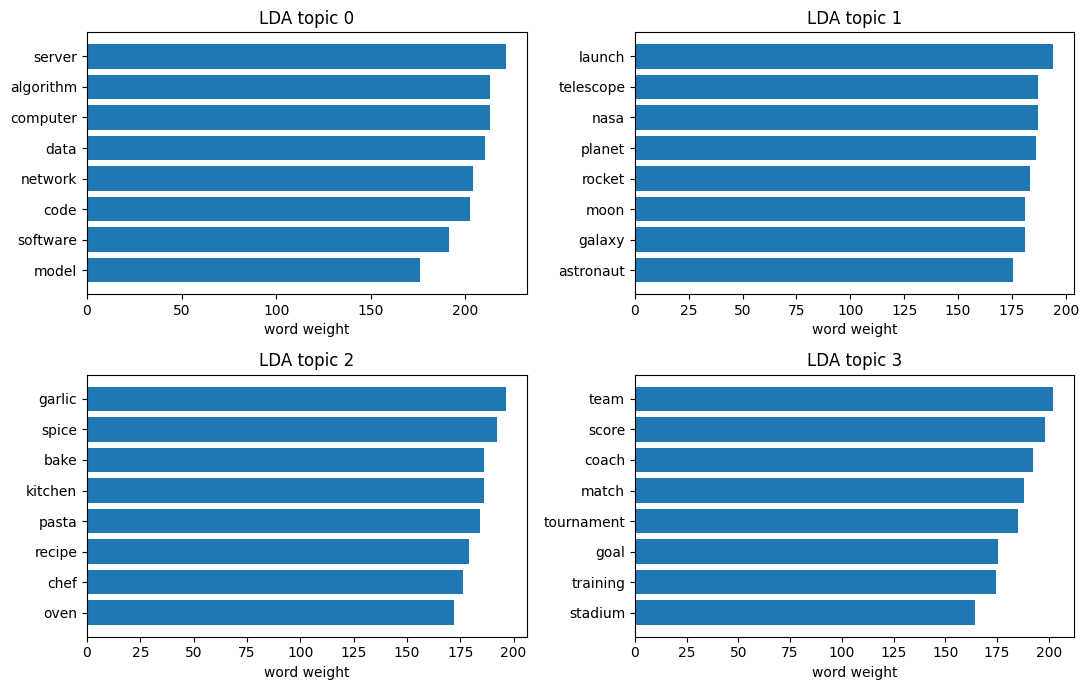

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for topic_idx, ax in enumerate(axes.ravel()):
    top_idx = np.argsort(lda.components_[topic_idx])[::-1][:8]
    ax.barh(
        feature_names[top_idx][::-1],
        lda.components_[topic_idx][top_idx][::-1],
        color="tab:blue",
    )
    ax.set_title(f"LDA topic {topic_idx}")
    ax.set_xlabel("word weight")
plt.tight_layout()
plt.show()

The exact topic numbers are arbitrary: LDA may call the space topic "topic 2" and the food topic
"topic 0". What matters is that each learned topic concentrates on a coherent set of words. The
adjusted Rand index compares the discovered partition with the known labels while ignoring label names.

## 4. Non-negative matrix factorization

NMF factorizes the document-term matrix into two non-negative matrices: document-topic and topic-word.
It is often faster than LDA and can produce sharper topics on short documents. We fit NMF on TF-IDF
weights, which emphasize distinctive terms.

In [7]:
tfidf_vectorizer = TfidfVectorizer(
    stop_words="english", max_df=0.9, min_df=2
)
X_tfidf = tfidf_vectorizer.fit_transform(documents)
tfidf_features = tfidf_vectorizer.get_feature_names_out()

nmf = NMF(
    n_components=n_topics,
    init="nndsvda",
    max_iter=500,
    random_state=42,
)
nmf.fit(X_tfidf)

nmf_topics = top_words(nmf.components_, tfidf_features, n_words=8)
print(nmf_topics.to_string(index=False))

nmf_doc_topic = nmf.transform(X_tfidf)
nmf_pred = nmf_doc_topic.argmax(axis=1)
print("adjusted Rand index (NMF vs true topics):",
      round(adjusted_rand_score(true_topics, nmf_pred), 3))

 topic                                                         top_words
     0 computer, server, data, network, algorithm, code, software, model
     1    team, score, match, coach, goal, tournament, training, stadium
     2  launch, telescope, nasa, rocket, moon, galaxy, planet, astronaut
     3         garlic, spice, kitchen, pasta, chef, bake, recipe, flavor
adjusted Rand index (NMF vs true topics): 1.0


LDA models counts with a generative probability model; NMF is a matrix-factorization method. Neither is
universally better. Compare them on your own corpus by inspecting topic coherence, stability, and
usefulness for the downstream task.

## 5. Choosing the number of topics

More topics can fit the training text better while becoming harder to interpret. Two common guides are:

- **Perplexity:** lower values indicate a better probabilistic fit on held-out text, but perplexity
  does not guarantee human-interpretable topics.
- **Interpretability and stability:** do the top words form coherent themes? Do topics remain similar
  across random seeds and data subsets?

We fit LDA for several topic counts and plot training perplexity.

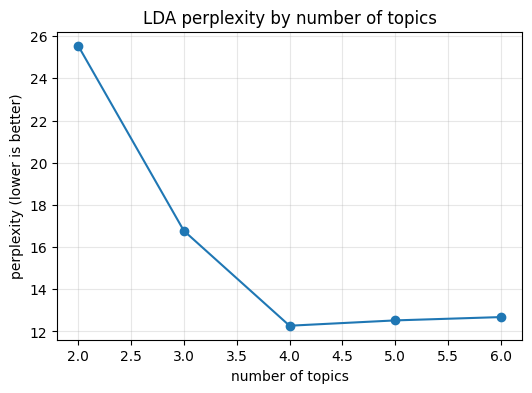

   topics  perplexity
0       2       25.55
1       3       16.77
2       4       12.27
3       5       12.52
4       6       12.68


In [8]:
topic_counts = [2, 3, 4, 5, 6]
perplexities = []
for k in topic_counts:
    model = LatentDirichletAllocation(
        n_components=k,
        learning_method="batch",
        max_iter=30,
        random_state=0,
    )
    model.fit(X_counts)
    perplexities.append(model.perplexity(X_counts))

plt.figure(figsize=(6, 4))
plt.plot(topic_counts, perplexities, marker="o")
plt.xlabel("number of topics")
plt.ylabel("perplexity (lower is better)")
plt.title("LDA perplexity by number of topics")
plt.grid(alpha=0.3)
plt.show()

print(pd.DataFrame({"topics": topic_counts, "perplexity": np.round(perplexities, 2)}))

Perplexity often keeps improving as the number of topics grows. That is why topic count is ultimately a
modeling choice: choose the smallest number that captures the distinctions you need, and validate the
topics with domain experts.

## 6. Inspecting document mixtures

A document is rarely 100% one topic. The document-topic matrix shows how much each topic contributes.
This is useful for routing support tickets, summarizing a corpus, or finding mixed-topic documents.

In [9]:
example_indices = [0, 1, 2, 3]
rows = []
for idx in example_indices:
    rows.append({
        "document": idx,
        "true topic": topic_names[true_topics[idx]],
        "dominant LDA topic": int(lda_pred[idx]),
        "mixture": np.round(doc_topic[idx], 2),
    })
print(pd.DataFrame(rows).to_string(index=False))

 document true topic  dominant LDA topic                  mixture
        0      space                   1 [0.01, 0.96, 0.01, 0.01]
        1       food                   2 [0.01, 0.01, 0.96, 0.01]
        2     sports                   3 [0.01, 0.01, 0.01, 0.96]
        3 technology                   0 [0.96, 0.01, 0.01, 0.01]


A document can have a dominant topic and still contain secondary themes. If a mixture is nearly
uniform, the document may be too short, off-topic, or a blend of several themes. Inspect those cases
instead of forcing a single label.

## 7. Limitations and good practice

- **Bag-of-words:** word order and negation are lost. "not good" and "good" can look similar.
- **Short text:** tweets and search queries provide little co-occurrence evidence.
- **Domain vocabulary:** generic stop-word lists may remove meaningful terms; build a domain-specific
  list.
- **Topic number:** there is no single correct value; evaluate stability and usefulness.
- **Non-negative components:** NMF cannot represent subtractive relationships.
- **Causality:** topics are descriptive patterns, not causal explanations.

A practical workflow is: preprocess, fit several models, inspect top words, check stability, and
validate with downstream tasks or human review.

## 8. Summary

- Topic modeling discovers latent themes without labels.
- Count and TF-IDF matrices provide the numerical representation.
- LDA is a generative mixture model; NMF is a non-negative factorization.
- Top words and document-topic mixtures make the output inspectable.
- Perplexity guides model fit, but interpretability and stability decide usefulness.
- The bag-of-words assumption is the main limitation.

## Exercises

1. Add a fifth synthetic topic (for example, finance) and see whether LDA recovers it.
2. Remove stop-word filtering and compare the topics.
3. Run LDA with five random seeds and measure how often the same top words appear.
4. Fit NMF on raw counts instead of TF-IDF and compare the top words.
5. Find a document with a nearly uniform topic mixture and explain why it is ambiguous.